<a href="https://colab.research.google.com/github/sessm216/randomprojects/blob/main/Ballistic2DFET.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Task

Numerically compute the I-V characteristic of a ballistic 2D FET with a single mode and a self-consistent solution for the potential U.

### Part a:
Plot the results obtained for the following situation: T = 1 K and T = 298 K, in the voltage range 0 < V_DS < 0.5 V, and V_GS = 0.3 V, 0.35 V, 0.4 V, 0.45 V and 0.5 V. At equilibrium, E_C = −4.7 eV and E_F = −5.0 eV, L = 40 nm, W = 3×L, and C_G = 0.1 fF, C_D = C_S = 0 F. Assume the effective mass m_eff = 0.5 × m₀ = 0.5 · 9.1 · 10⁻³¹ kg.

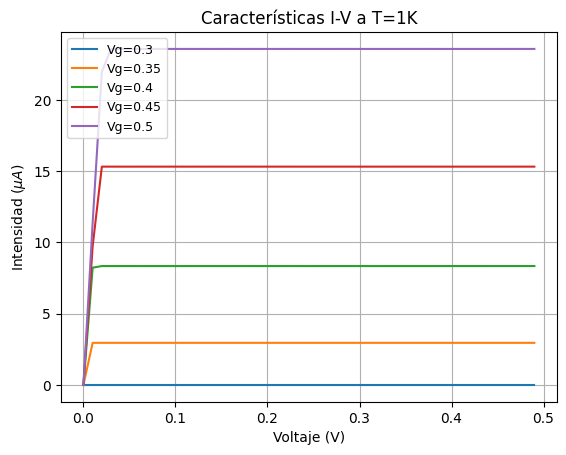

In [1]:

#Import de paquetes necesarios
import numpy as np
from scipy import constants as con
from scipy.integrate import quad
import math
import matplotlib.pyplot as plt


#Definición de funciones iniciales

def f(E,mu):  #Función de Fermi
    A=100
    if E > mu +A*K*T: #Control de la f para que no explote: exp->inf
        return 0.0
    elif E < mu -A*K*T: #control: exp->0
        return 1.0
    else:
        return 1/(1+np.exp((E-mu)/(K*T)))


def inten(E,mu,omega): #función a integrar
    return math.sqrt(E-omega)*f(E,mu)

#Parámetros, constantes iniciales

q=con.elementary_charge
K=con.Boltzmann/q
hbar=con.hbar/q
h=con.h/q
me=con.electron_mass #kg

E_f=-5 #Nivel de fermi que coincide con el nivel químico de la fuente
Ec_i=-4.7
T=1
L=4e-8
W=3*L
Ar=L*W
gamma=0.1
mef=0.5*me
tau=con.hbar/q/0.1

Cg=0.1*1e-15
Cd=0
Cs=0
Ces=Cg+Cd+Cs
Cq=q*mef*W*L/(2*con.pi*hbar**2)

eta0=Cg/(Cs+Cd+Cg)
eta=Cg/(Cs+Cd+Cg+Cq)
Vt=(Ec_i-E_f)/(eta0)


Vds_i=0 #Voltaje inicial drain-source
Vds_f=0.5 #Voltajel final
paso_ds=0.01

#Voltaje gate-source
Vgs_i=0.3
Vgs_f=0.5
paso_g=0.05

#Vectores
Vds=Vds_i
Vg=Vgs_i


#Valor inicial de N0
Ec1=Ec_i
N_0,_=quad(lambda E: f(E,E_f),Ec1,np.inf) #integro
N_0=(L*W*mef/(q*con.pi*hbar**2))*N_0 #constantes

#Bucle en g
while Vg<Vgs_f:
    i=0
    Vds=Vds_i
    V=np.zeros(int(((np.abs(Vds_i)+np.abs(Vds_f))/paso_ds)))
    It=np.zeros(int(((np.abs(Vds_i)+np.abs(Vds_f))/paso_ds))) #Inicialización de las matrices
    I_0=0
    V_0=0
    #Bucle en Vds para 1 valor de Vgs
    while Vds<Vds_f:

        #Calculo los niveles de la fuente y el drenador para el potencial dado
        mu_s=E_f
        mu_d=E_f-Vds
        error=1
        alfa=0.01
        U=-Vg*(Cg/Ces)
        iter=0
        while error>0.0001 and iter<10000:
            #Numero de electrones N
            Ns1,_=quad(lambda E: f(E,mu_s),U+Ec1-Vg,np.inf)
            Nd1,_=quad(lambda E: f(E,mu_d),U+Ec1-Vg,np.inf)
            N=(Ns1+Nd1)*(L*W*mef/(q*con.pi*hbar**2))/2
            #Antes de calcular el nuevo U, lo guardo
            Uold=U
            #calculo el nuevo U
            U=(q/Ces)*(N-N_0)
            #calculo el error
            error=np.abs(U-Uold)
            #para que U converja
            U=Uold+alfa*(U-Uold)
            iter=iter+1
        U=U-Vg
        Is,_=quad(lambda E: inten(E,mu_s,Ec1+U),Ec1+U,np.inf)
        Id,_=quad(lambda E: inten(E,mu_d,Ec1+U),Ec1+U,np.inf)
        I=(Is-Id)*(W*math.sqrt(2*mef*q))/((np.pi*hbar)**2)
        #Ahora lo guardo en un vector para representarlo luego
        V[i]=Vds
        It[i]=I*1e6#multiplico por 1e9 para conseguir nanoamperios
        I_0=I
        V_0=Vds
        #Aumento contadores
        i=i+1
        Vds=Vds+paso_ds

    #Graficación
    plt.plot(V, It,label='Vg='+str(round(Vg,2)))
    plt.legend(loc='lower right')
    plt.title('Características I-V a T=1K')
    plt.xlabel('Voltaje (V)')
    plt.ylabel(r'Intensidad ($\mu A$)')
    Vg=Vg+paso_g


plt.grid(True)
plt.legend(fontsize=9)
plt.show()

### Part b:

Compare your numerical results with the analytical solutions for the linear and saturation regions (Eqs. (5.60) and (5.61)). Explain the discrepancies. (Script adapted with Claude bc the original needed to read a txt, in this version the content of the txt is computed)

V_T = 0.300 V,  Nint = 1000
Vgs = 0.000 V   I = 3.3007e-10 A
Vgs = 0.100 V   I = 1.6161e-08 A
Vgs = 0.200 V   I = 6.8755e-07 A
Vgs = 0.300 V   I = 7.7532e-06 A
Vgs = 0.400 V   I = 2.2344e-05 A
Vgs = 0.500 V   I = 4.0900e-05 A
Vgs = 0.600 V   I = 6.2400e-05 A
Vgs = 0.700 V   I = 8.6539e-05 A
Vgs = 0.800 V   I = 1.1318e-04 A
Vgs = 0.900 V   I = 1.4222e-04 A
Vgs = 1.000 V   I = 1.7358e-04 A
Done.
Saved nano.txt and el.txt


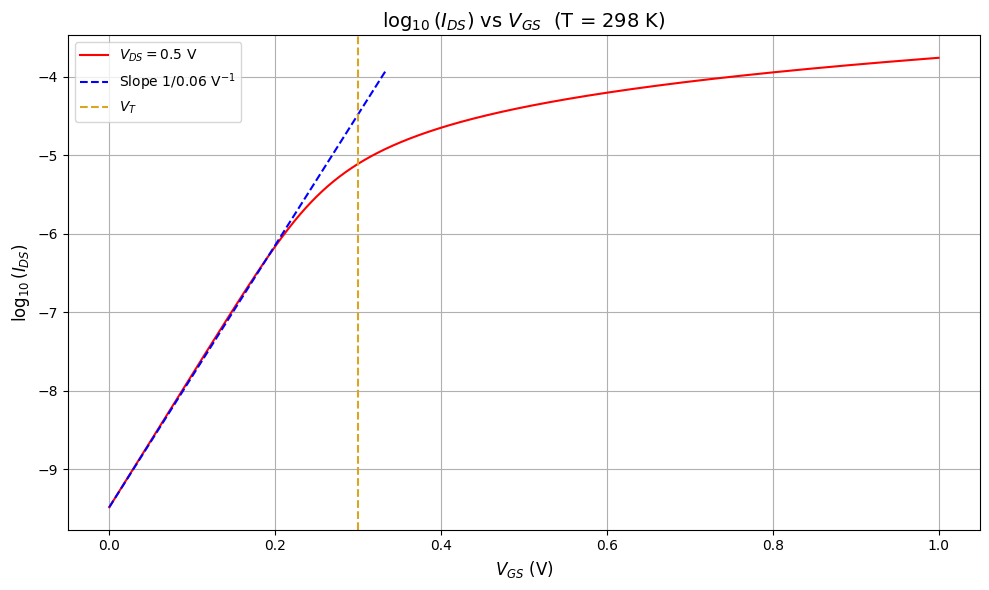

In [4]:
##Created on Sun May 18 19:57:21 2025

##@author: sanch

import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import constants as con
from scipy.integrate import quad

q    = con.elementary_charge
K    = con.Boltzmann / q      # Boltzmann constant [eV/K]
hbar = con.hbar / q           # reduced Planck constant [eV·s]
me   = con.electron_mass      # electron mass [kg]

##Parameters
T   = 298        # temperature [K]
E_c = -4.7       # conduction band edge at equilibrium [eV]
E_f = -5.0       # Fermi level (= source chemical potential) [eV]
m   = 0.5 * me   # effective mass [kg]
L   = 40e-9      # channel length [m]
W   = 3 * L      # channel width [m]
Cg  = 0.1e-15    # gate capacitance [F]
Cd  = 0.0        # drain capacitance [F]
Cs  = 0.0        # source capacitance [F]
Vds = 0.5        # drain-source voltage [V]

# --- Gate-voltage sweep
Vgs_i, Vgs_f, paso_gs = 0.0, 1.0, 0.001      # [V]
Nint = int(abs(Vgs_f - Vgs_i) / paso_gs)

# --- Self-consistency (iterative U)
epsilon = 1e-6   # convergence tolerance on U [eV]
alfa    = 0.1    # under-relaxation factor
Nit_max = 1000   # maximum number of iterations

# --- Derived constants
Ces  = Cg + Cd + Cs                                   # total electrostatic capacitance
aux2 = q / Ces                                        # q^2/C_ES expressed in eV per electron
AUX  = (W * math.sqrt(2 * m * q)) / ((np.pi * hbar)**2)   # prefactor of the current
AUX2 = (L * W * m) / (q * np.pi * hbar**2)            # prefactor of the electron number
eta0 = Cg / Ces
V_T  = (E_c - E_f) / eta0                             # threshold voltage [V]
print(f"V_T = {V_T:.3f} V,  Nint = {Nint}")


def fermi(E, mu, T):
    A = 100
    if E > mu + A * K * T:       # exp -> inf
        return 0.0
    elif E < mu - A * K * T:     # exp -> 0
        return 1.0
    return 1 / (np.exp((E - mu) / (K * T)) + 1)


def current_integrand(E, mu, omega, T):
    # sqrt(E - E_c - U) * f(E, mu); omega = E_c + U is the band edge
    return math.sqrt(E - omega) * fermi(E, mu, T)


# Equilibrium electron number N0 (source and drain at E_f, band edge at E_c)
N0 = AUX2 * quad(lambda E: fermi(E, E_f, T), E_c, np.inf)[0]


def solve_charging(Vgs):
    # Self-consistent U for a given Vgs. Returns (U_f, iterations, converged).
    Uc  = [0.0, 2 * epsilon]     # [new U, previous U]
    Nit = 0
    while True:
        lower = E_c + Uc[0] - Vgs
        Ns, _ = quad(lambda E: fermi(E, E_f,       T), lower, np.inf)
        Nd, _ = quad(lambda E: fermi(E, E_f - Vds, T), lower, np.inf)
        N = AUX2 * (Ns + Nd) / 2
        Uc[1] = Uc[0]
        Uc[0] = Uc[1] + alfa * (aux2 * (N - N0) - Uc[1])
        converged = abs(Uc[0] - Uc[1]) < epsilon
        if converged or Nit > Nit_max:
            return Uc[0] - Vgs, Nit, converged
        Nit += 1


def drain_current(Vgs):
    # I_DS [A] for a given Vgs.
    Uf, Nit, converged = solve_charging(Vgs)
    if not converged:
        print(f"Warning: U did not converge at Vgs = {Vgs:.3f} V")
    edge = E_c + Uf
    i1, _ = quad(lambda E: current_integrand(E, E_f,       edge, T), edge, np.inf)
    i2, _ = quad(lambda E: current_integrand(E, E_f - Vds, edge, T), edge, np.inf)
    return AUX * (i1 - i2)

Vgs_vec = Vgs_i + np.arange(Nint + 1) * paso_gs
I = np.zeros(Nint + 1)

for j, Vgs in enumerate(Vgs_vec):
    I[j] = drain_current(Vgs)
    if j % 100 == 0:
        print(f"Vgs = {Vgs:.3f} V   I = {I[j]:.4e} A")
print("Done.")

# Files are written in the notebook's working folder (mode "w": they are overwritten, not appended).
np.savetxt("nano.txt", np.column_stack((Vgs_vec, I)), fmt="%.10g", header="Vgs[V]  I[A]")
np.savetxt("el.txt",   np.column_stack((Vgs_vec, np.log10(I))), fmt="%.10g", header="Vgs[V]  log10(I)")
print("Saved nano.txt and el.txt")


logI = np.log10(I)

# Ideal subthreshold line (first third of the sweep)
n_sub = int(Nint / 3) + 1
S = np.log10(I[0]) + Vgs_vec[:n_sub] / 0.06

plt.figure(figsize=(10, 6))
plt.plot(Vgs_vec, logI, color="red", label=rf"$V_{{DS}} = {Vds}$ V")
plt.plot(Vgs_vec[:n_sub], S, "--", color="blue", label=r"Slope $1/0.06$ V$^{-1}$")
plt.axvline(x=V_T, color="goldenrod", linestyle="--", label=r"$V_T$")
plt.title(rf"$\log_{{10}}(I_{{DS}})$ vs $V_{{GS}}$  (T = {T} K)", fontsize=14)
plt.xlabel(r"$V_{GS}$ (V)", fontsize=12)
plt.ylabel(r"$\log_{10}(I_{DS})$", fontsize=12)
plt.legend(); plt.grid(True); plt.tight_layout()
plt.show()

**Subthreshold slope.** For an ideal gate ($\eta=1$) the current falls by one decade for every $60$ mV below threshold at room temperature. The dashed line starts at $I(V_{GS}=0)$ and has slope $1/0.06\ \mathrm{V}^{-1}$ in $\log_{10}I$, for comparison with the numerical curve. The vertical line marks $V_T=(E_C-E_F)/\eta_0$.

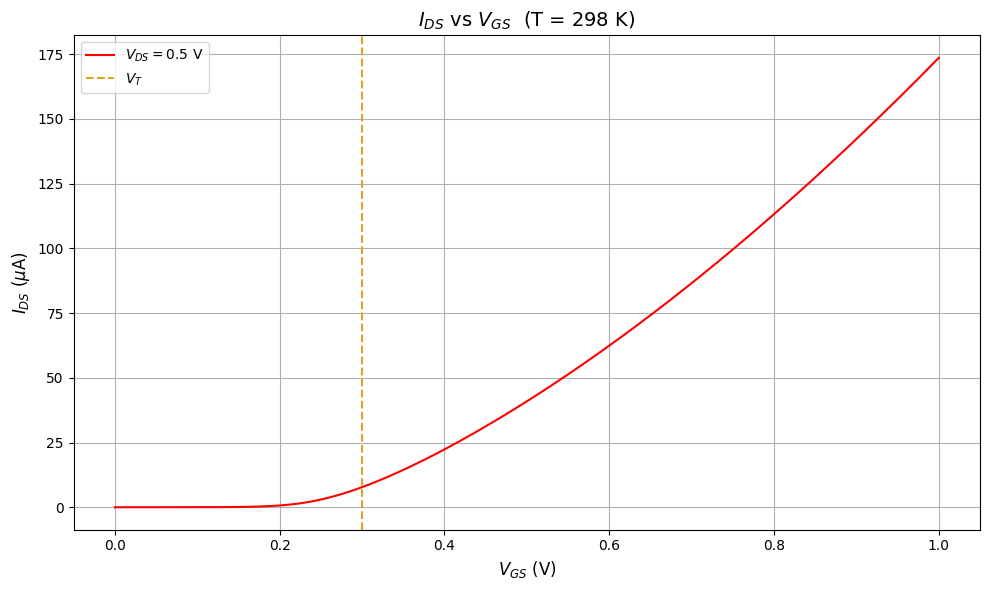

In [5]:
plt.figure(figsize=(10, 6))
plt.plot(Vgs_vec, I * 1e6, color="red", label=rf"$V_{{DS}} = {Vds}$ V")
plt.axvline(x=V_T, color="goldenrod", linestyle="--", label=r"$V_T$")
plt.title(rf"$I_{{DS}}$ vs $V_{{GS}}$  (T = {T} K)", fontsize=14)
plt.xlabel(r"$V_{GS}$ (V)", fontsize=12)
plt.ylabel(r"$I_{DS}$ ($\mu$A)", fontsize=12)
plt.legend(); plt.grid(True); plt.tight_layout()
plt.show()

Commenting the results:

For the numerical development it was assumed that $V_DS > η(V_{GS} − V_T)$ or $V_DS < η(V_{GS} - V_T)$, but never equal. As V increases in the region near $V_T$, the numerical and analytical results become different; the curvature increases until it enters the saturation regime, where it stabilizes.

### Part c:
Numerically determine $I_DS$ vs. $V_GS$ when $V_DS$ = 0.5 V and T = 298 K. Plot the current on a logarithmic scale and show that the subthreshold slope is 60 mV/decade.

Answer:
The results are shown in the plot below:


The values of $log(I_{DS})$ versus $V_{GS}$ have been plotted, together with a fitted line:
$$
f(x) = 16.67x - 9.481
$$
The slope $m = 16.67 V⁻¹$ corresponds to the inverse of the subthreshold slope, so that $m⁻¹ = 0.059988 V$. Therefore, the subthreshold slope is indeed 60 mV/decade.

### Part d:

Use the previous part to estimate a new value of $V_T$ so that the analytical solution for the saturation region (Eq. (5.61)) gives a better fit at T = 300 K. Comment on your choice.



For this part, a linear fit of the form f(x) = mx + n was performed on the data of $log(I_{DS})$ versus voltage {V_GS} in the interval (0.25, 0.549) V, corresponding to Figure:
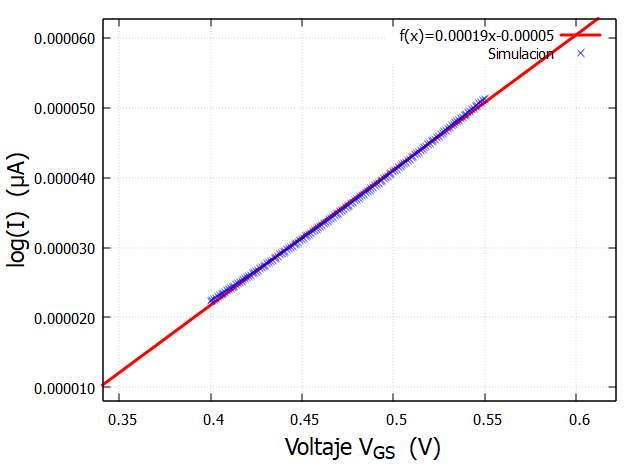
The fit is:

f(x) = 0.00019x - 0.00005 (4)

The threshold voltage $V_T$ can be obtained from $log(I_{DS})(V_T) = 0$, giving $V_T$ = 0.287, close to the value initially considered, $V_T = 0.3 V$.

